In [ ]:

from google.colab import files

uploaded = files.upload()


Saving dataset.csv to dataset.csv


In [ ]:
import pandas as pd
import numpy as np

# Automatically find uploaded CSV file
filename = next(name for name in uploaded.keys() if name.lower().endswith(".csv"))
df = pd.read_csv(filename, encoding="utf-8")

# Detect text and language columns
def find_column(columns, candidates):
    lookup = {str(c).strip().lower(): c for c in columns}
    for candidate in candidates:
        if candidate in lookup:
            return lookup[candidate]
    return None

text_col = find_column(df.columns, ["text", "texts", "sentence", "content", "text_snippet"])
label_col = find_column(df.columns, ["language", "lang", "label", "labels"])

df = df[[text_col, label_col]].copy()
df.columns = ["text", "language"]

# Drop nulls, clean whitespace, and remove duplicates
df = df.dropna(subset=["text", "language"])
df["text"] = df["text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()
df = df[(df["text"] != "") & (df["language"] != "")].drop_duplicates()

print(f"Cleaned Dataset Shape: {df.shape}")
print(f"Number of Languages: {df['language'].nunique()}")

Cleaned Dataset Shape: (21858, 2)
Number of Languages: 22


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

MAX_LANGUAGES = 20
SAMPLES_PER_LANGUAGE = 1000

top_languages = df["language"].value_counts().head(MAX_LANGUAGES).index
df = df[df["language"].isin(top_languages)]

# Sample equal records per language
df = df.groupby("language", group_keys=False).apply(
    lambda g: g.sample(n=min(len(g), SAMPLES_PER_LANGUAGE), random_state=42)
).reset_index(drop=True)

encoder = LabelEncoder()
y = encoder.fit_transform(df["language"])
X = df["text"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 15944
Testing samples: 3986


/tmp/ipykernel_721/4207150165.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby("language", group_keys=False).apply(


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 30000
MAX_LEN = 150

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>",
    char_level=True  # Crucial for cross-script language detection
)
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post")
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding="post", truncating="post")

print("Training sequence shape:", X_train_pad.shape)
print("Testing sequence shape:", X_test_pad.shape)

Training sequence shape: (15944, 150)
Testing sequence shape: (3986, 150)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

num_classes = len(encoder.classes_)

model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=64, mask_zero=True),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 97ms/step - accuracy: 0.2134 - loss: 2.4186 - val_accuracy: 0.3187 - val_loss: 1.8493
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 10s 103ms/step - accuracy: 0.3945 - loss: 1.6339 - val_accuracy: 0.5575 - val_loss: 1.2955
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 10s 103ms/step - accuracy: 0.5111 - loss: 1.2982 - val_accuracy: 0.4125 - val_loss: 1.4492
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 10s 96ms/step - accuracy: 0.5509 - loss: 1.1881 - val_accuracy: 0.6125 - val_loss: 1.0240
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 10s 89ms/step - accuracy: 0.6506 - loss: 0.9476 - val_accuracy: 0.6450 - val_loss: 0.9089
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 10s 103ms/step - accuracy: 0.6816 - loss: 0.8513 - val_accuracy: 0.6587 - val_loss: 0.9048
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 10s 103ms/step - accuracy: 0.6938 - loss: 0.8227 - val_accuracy: 0.6963 - val_loss: 0.8844
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 12s 120ms/step - accuracy: 0.7098 - loss: 0.80

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

y_prob = model.predict(X_test_pad, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print(f"Test Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision:      {precision_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print(f"Recall:         {recall_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print(f"F1-score:       {f1_score(y_test, y_pred, average='weighted', zero_division=0):.4f}\n")

print("Classification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=encoder.classes_,
    zero_division=0
))

Test Accuracy:  0.7710
Precision:      0.7727
Recall:         0.7710
F1-score:       0.7533

Classification Report:

              precision    recall  f1-score   support

      Arabic       0.99      1.00      1.00       100
     Chinese       0.99      0.97      0.98       100
       Dutch       0.50      0.05      0.09       100
     English       0.36      0.70      0.47       100
    Estonian       0.64      0.62      0.63       100
      French       0.28      0.25      0.26       100
       Hindi       0.94      0.99      0.97       100
    Japanese       0.98      0.97      0.97       100
      Korean       1.00      0.99      0.99       100
     Persian       0.98      0.96      0.97       100
   Portugese       0.25      0.15      0.19       100
      Pushto       0.99      0.94      0.96       100
    Romanian       0.53      0.90      0.67       100
     Russian       0.96      0.98      0.97       100
     Spanish       0.65      0.33      0.44       100
     Swedish      

In [ ]:
def predict_language():
    while True:
        text = input("Enter text (or type 'exit' to stop): ").strip()
        if text.lower() == "exit":
            print("Stopped.")
            break
        if not text:
            continue

        seq = tokenizer.texts_to_sequences([text])
        if not seq[0]:
            print("Unknown input character.")
            continue

        padded = pad_sequences(seq, maxlen=MAX_LEN, padding="post", truncating="post")
        pred = model.predict(padded, verbose=0)

        pred_id = int(np.argmax(pred, axis=1)[0])
        lang = encoder.inverse_transform([pred_id])[0]
        conf = float(np.max(pred)) * 100

        print("-" * 40)
        print(f"Input Text: {text}")
        print(f"Predicted Language: {lang}")
        print(f"Confidence: {conf:.2f}%")
        print("-" * 40)

predict_language()

Enter text (or type 'exit' to stop): 你好，很高兴认识你。
----------------------------------------
Input Text: 你好，很高兴认识你。
Predicted Language: Chinese
Confidence: 52.12%
----------------------------------------
Enter text (or type 'exit' to stop): 你好，很高兴认识你。
----------------------------------------
Input Text: 你好，很高兴认识你。
Predicted Language: Chinese
Confidence: 52.12%
----------------------------------------
Enter text (or type 'exit' to stop): नमस्ते, आप कैसे हैं?
----------------------------------------
Input Text: नमस्ते, आप कैसे हैं?
Predicted Language: Hindi
Confidence: 96.61%
----------------------------------------
Enter text (or type 'exit' to stop): こんにちは、お元気ですか？
----------------------------------------
Input Text: こんにちは、お元気ですか？
Predicted Language: Japanese
Confidence: 97.66%
----------------------------------------
Enter text (or type 'exit' to stop): 안녕하세요, 만나서 반갑습니다.
----------------------------------------
Input Text: 안녕하세요, 만나서 반갑습니다.
Predicted Language: Korean
Confidence: 67.91%
---

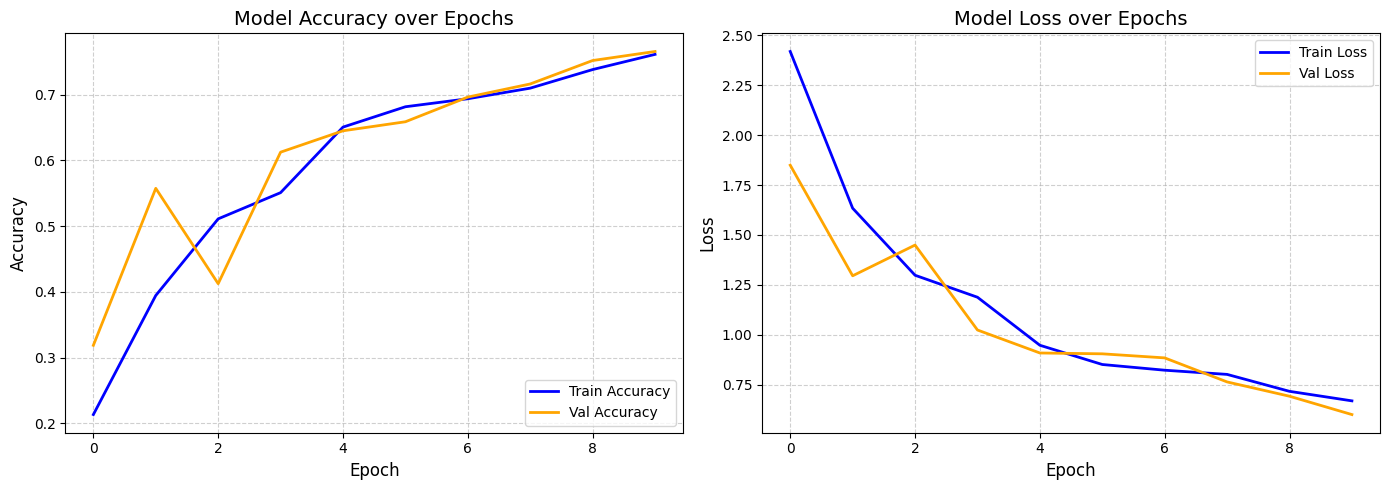

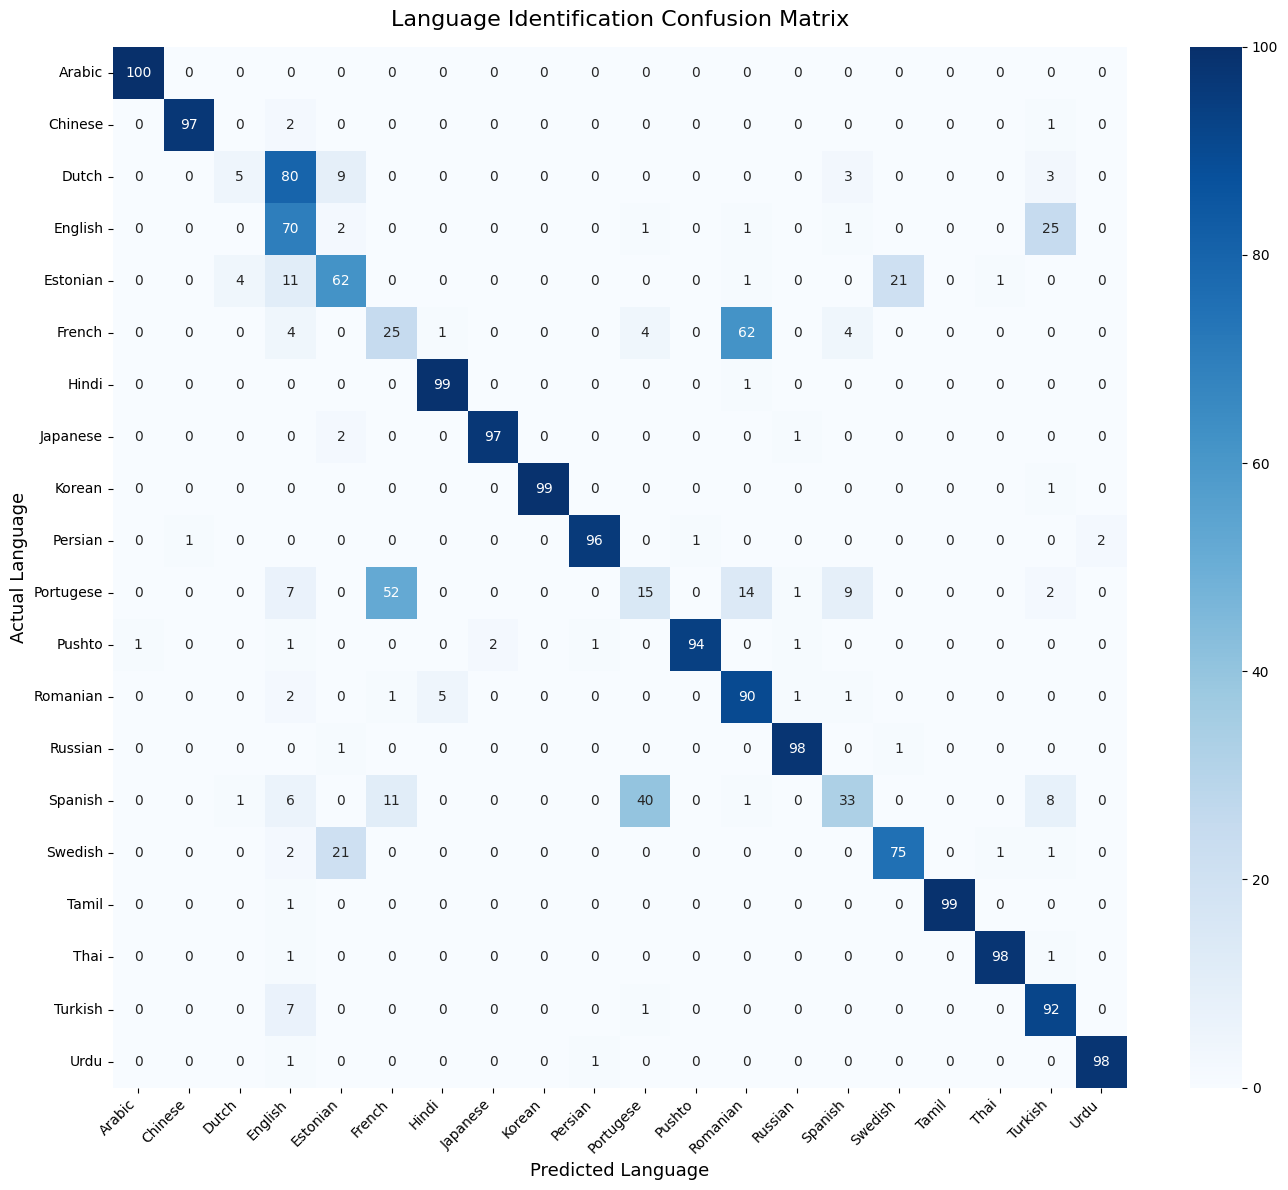

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# ==========================================
# 1. Training & Validation Performance Graphs
# ==========================================
plt.figure(figsize=(14, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', color='blue', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Val Accuracy', color='orange', linewidth=2)
plt.title('Model Accuracy over Epochs', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', color='blue', linewidth=2)
plt.plot(history.history['val_loss'], label='Val Loss', color='orange', linewidth=2)
plt.title('Model Loss over Epochs', fontsize=14)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# ==========================================
# 2. Confusion Matrix Heatmap
# ==========================================
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_,
    cbar=True
)
plt.title('Language Identification Confusion Matrix', fontsize=16, pad=15)
plt.xlabel('Predicted Language', fontsize=13)
plt.ylabel('Actual Language', fontsize=13)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()